In [7]:
# Core library imports
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tifffile as tiff
import torch

# Local imports
os.environ["NEURITE_BACKEND"] = "pytorch"
os.environ["VXM_BACKEND"] = "pytorch"
import neurite as ne
import voxelmorph_folder.voxelmorph as vxm
from scripts.utils.configs import HEIGHT, TRAIN_DATA, TRAIN_DATA_2, WIDTH, device  # noqa: F401
from scripts.utils.utils import interpole_and_pad, iou, relabel_cells, visualize_labels


ImportError: voxelmorph requires neurite version 0.2 or greater, but found version None

# Dice over time (in binary)

In [15]:
# Load video frames
frames_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02").iterdir())
seg_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02_ERR_SEG").iterdir())

#TODO add : for idx in range(len(seg_path_list) - 1):
res_dice = {}
res_iou = {}
for gap in range(1, len(frames_path_list) - 1):
    idx = 0
    idx2 = idx + gap
    seg_moving = tiff.imread(seg_path_list[idx])
    seg_fixed = tiff.imread(seg_path_list[idx2])
    seg_moving = np.where(seg_moving > 0, 1, 0)
    seg_fixed = np.where(seg_fixed > 0, 1, 0)
    seg_moving = interpole_and_pad(seg_moving, [HEIGHT, WIDTH])
    seg_fixed = interpole_and_pad(seg_fixed, [HEIGHT, WIDTH])
    # Check if nbr of cells different
    labels_moving = np.sort(np.unique(seg_moving))
    labels_fixed = np.sort(np.unique(seg_fixed))
    if len(labels_moving) != len(labels_fixed):
        print(  # noqa: T201
            f"Different number of cells for pair {idx}-{idx2} {len(labels_moving)} vs {len(labels_fixed)}, skipping evaluation for this pair."  # noqa: E501
        )
        continue
    # Compute Dice score
    dice = vxm.py.utils.dice(seg_moving, seg_fixed, include_zero=False)
    res_dice[f"{gap}"] = np.mean(dice)
    # Compute IoU score
    iou_score = iou(seg_moving, seg_fixed, include_zero=False)
    res_iou[f"{gap}"] = np.mean(iou_score)

print("Dice scores:", res_dice)  # noqa: T201
print("IoU scores:", res_iou)  # noqa: T201

Dice scores: {'1': np.float64(0.9439700997774653), '2': np.float64(0.9127310061601642), '3': np.float64(0.8722453099804665), '4': np.float64(0.8336712174091563), '5': np.float64(0.8163752962678326), '6': np.float64(0.7935098273090286), '7': np.float64(0.7687639006866858), '8': np.float64(0.7468677554635201), '9': np.float64(0.7328324596916483), '10': np.float64(0.7118122598329989), '11': np.float64(0.7116481867229043), '12': np.float64(0.6846643360636496), '13': np.float64(0.7043389443803308), '14': np.float64(0.697715928998777), '15': np.float64(0.6930088384918625), '16': np.float64(0.6746675273520093), '17': np.float64(0.6506859641188), '18': np.float64(0.6309371530235246), '19': np.float64(0.6071092794127118), '20': np.float64(0.5926516743184707), '21': np.float64(0.5757281049819757), '22': np.float64(0.555243985198274), '23': np.float64(0.5412018940477326), '24': np.float64(0.526644606559262), '25': np.float64(0.5208416642863943), '26': np.float64(0.5094836169011941), '27': np.floa

Dice scores: {'1': np.float64(0.9439700997774653), '2': np.float64(0.9127310061601642), '3': np.float64(0.8722453099804665), '4': np.float64(0.8336712174091563), '5': np.float64(0.8163752962678326), '6': np.float64(0.7935098273090286), '7': np.float64(0.7687639006866858), '8': np.float64(0.7468677554635201), '9': np.float64(0.7328324596916483), '10': np.float64(0.7118122598329989), '11': np.float64(0.7116481867229043), '12': np.float64(0.6846643360636496), '13': np.float64(0.7043389443803308), '14': np.float64(0.697715928998777), '15': np.float64(0.6930088384918625), '16': np.float64(0.6746675273520093), '17': np.float64(0.6506859641188), '18': np.float64(0.6309371530235246), '19': np.float64(0.6071092794127118), '20': np.float64(0.5926516743184707), '21': np.float64(0.5757281049819757), '22': np.float64(0.555243985198274), '23': np.float64(0.5412018940477326), '24': np.float64(0.526644606559262), '25': np.float64(0.5208416642863943), '26': np.float64(0.5094836169011941), '27': np.floa

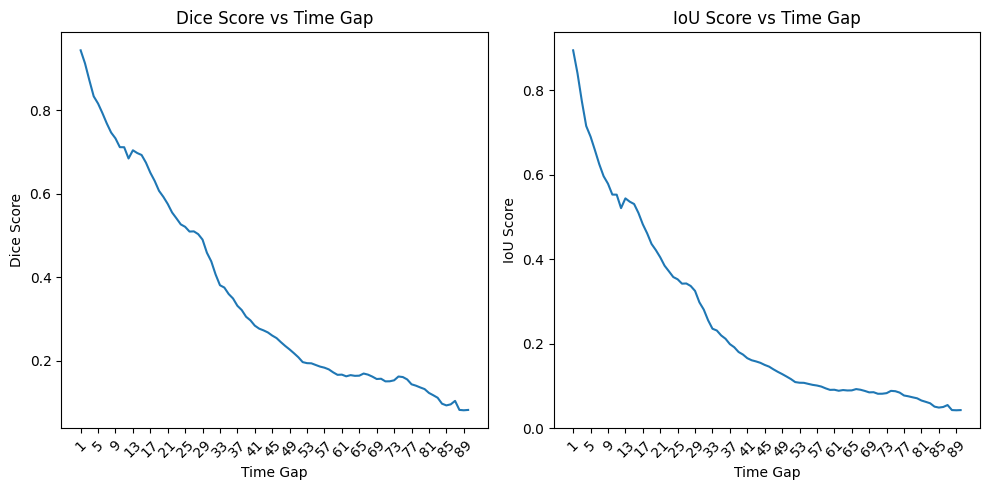

In [16]:
print("Dice scores:", res_dice)  # noqa: T201
print("IoU scores:", res_iou)  # noqa: T201
# Plot results
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(list(res_dice.keys()), list(res_dice.values()))
plt.xlabel("Time Gap")
plt.ylabel("Dice Score")
plt.title("Dice Score vs Time Gap")
plt.xticks(list(res_dice.keys())[::4], rotation=45)
plt.subplot(1, 2, 2)
plt.plot(list(res_iou.keys()), list(res_iou.values()))
plt.xlabel("Time Gap")
plt.ylabel("IoU Score")
plt.title("IoU Score vs Time Gap")
plt.xticks(list(res_iou.keys())[::4], rotation=45)
plt.tight_layout()
plt.show()

# Dice over time (with ERR_SEG_TRA)

In [17]:
# Load video frames
seg_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02_ERR_SEG_TRA").iterdir())

#TODO add : for idx in range(len(seg_path_list) - 1):
res_dice = {}
res_iou = {}
for gap in range(1, len(seg_path_list) - 1):
    idx = 0
    idx2 = idx + gap
    seg_moving = tiff.imread(seg_path_list[idx])
    seg_fixed = tiff.imread(seg_path_list[idx2])
    seg_moving = interpole_and_pad(seg_moving, [HEIGHT, WIDTH])
    seg_fixed = interpole_and_pad(seg_fixed, [HEIGHT, WIDTH])
    # Compute Dice score
    dice = vxm.py.utils.dice(seg_moving, seg_fixed, include_zero=False)
    res_dice[f"{gap}"] = np.mean(dice)
    # Compute IoU score
    iou_score = iou(seg_moving, seg_fixed, include_zero=False)
    res_iou[f"{gap}"] = np.mean(iou_score)

print("Dice scores:", res_dice)  # noqa: T201
print("IoU scores:", res_iou)  # noqa: T201

Dice scores: {'1': np.float64(0.9399053565398419), '2': np.float64(0.9068198855952209), '3': np.float64(0.864410832858282), '4': np.float64(0.7700566476613145), '5': np.float64(0.7788832719742307), '6': np.float64(0.7511502250888499), '7': np.float64(0.7247051544985782), '8': np.float64(0.7312115021547118), '9': np.float64(0.6946923045679031), '10': np.float64(0.6859820178525292), '11': np.float64(0.704142494759833), '12': np.float64(0.6590321022803447), '13': np.float64(0.6797303516291269), '14': np.float64(0.6730721011677624), '15': np.float64(0.6701209543701304), '16': np.float64(0.652988009581195), '17': np.float64(0.60614450546129), '18': np.float64(0.5671594295985725), '19': np.float64(0.5280452887650176), '20': np.float64(0.5319356937068834), '21': np.float64(0.5161850893552526), '22': np.float64(0.48210453468496156), '23': np.float64(0.47339565633651626), '24': np.float64(0.47805523788540727), '25': np.float64(0.4718074110277704), '26': np.float64(0.4613093296362862), '27': np.

Dice scores: {'1': np.float64(0.9399053565398419), '2': np.float64(0.9068198855952209), '3': np.float64(0.864410832858282), '4': np.float64(0.7700566476613145), '5': np.float64(0.7788832719742307), '6': np.float64(0.7511502250888499), '7': np.float64(0.7247051544985782), '8': np.float64(0.7312115021547118), '9': np.float64(0.6946923045679031), '10': np.float64(0.6859820178525292), '11': np.float64(0.704142494759833), '12': np.float64(0.6590321022803447), '13': np.float64(0.6797303516291269), '14': np.float64(0.6730721011677624), '15': np.float64(0.6701209543701304), '16': np.float64(0.652988009581195), '17': np.float64(0.60614450546129), '18': np.float64(0.5671594295985725), '19': np.float64(0.5280452887650176), '20': np.float64(0.5319356937068834), '21': np.float64(0.5161850893552526), '22': np.float64(0.48210453468496156), '23': np.float64(0.47339565633651626), '24': np.float64(0.47805523788540727), '25': np.float64(0.4718074110277704), '26': np.float64(0.4613093296362862), '27': np.

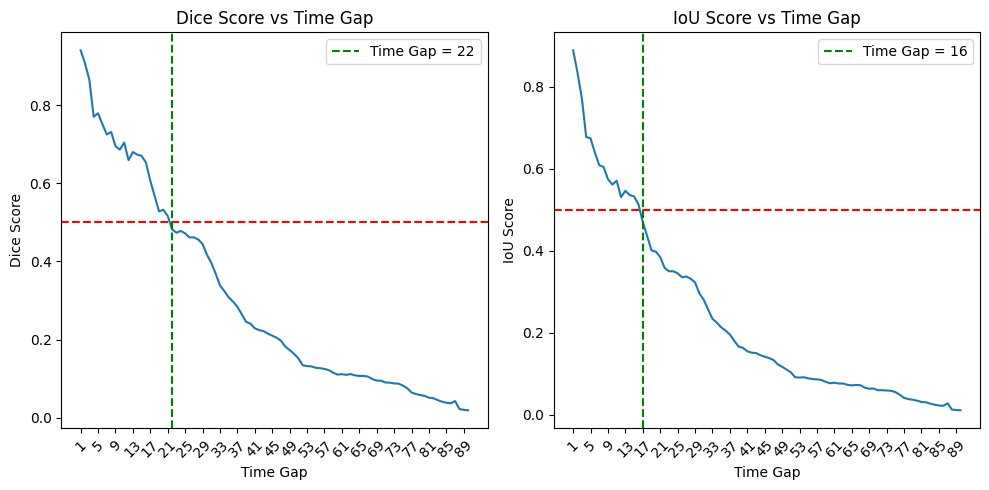

In [28]:
print("Dice scores:", res_dice)  # noqa: T201
print("IoU scores:", res_iou)  # noqa: T201
# Plot results
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(list(res_dice.keys()), list(res_dice.values()))
plt.xlabel("Time Gap")
plt.ylabel("Dice Score")
plt.title("Dice Score vs Time Gap")
plt.xticks(list(res_dice.keys())[::4], rotation=45)
plt.axhline(y=0.5, color="r", linestyle="--")
plt.axvline(x=21, color="g", linestyle="--", label="Time Gap = 22")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(list(res_iou.keys()), list(res_iou.values()))
plt.xlabel("Time Gap")
plt.ylabel("IoU Score")
plt.title("IoU Score vs Time Gap")
plt.xticks(list(res_iou.keys())[::4], rotation=45)
plt.axhline(y=0.5, color="r", linestyle="--")
plt.axvline(x=16, color="g", linestyle="--", label="Time Gap = 16")
plt.legend()
plt.tight_layout()
plt.show()

# Visualisation over time

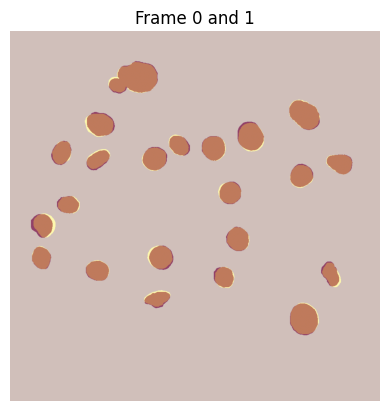

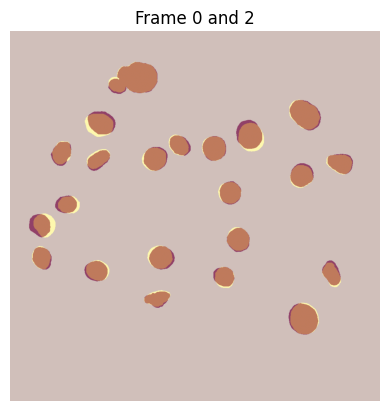

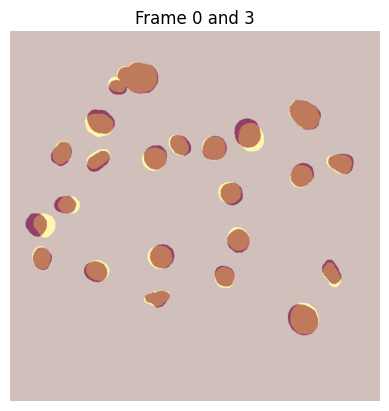

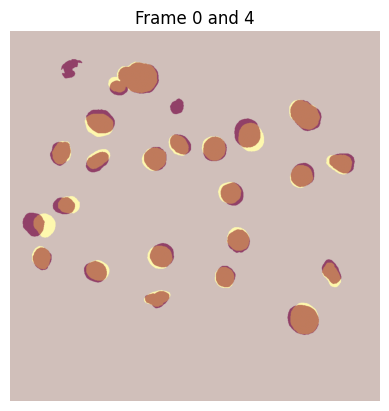

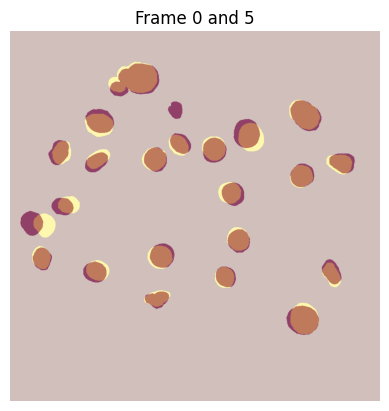

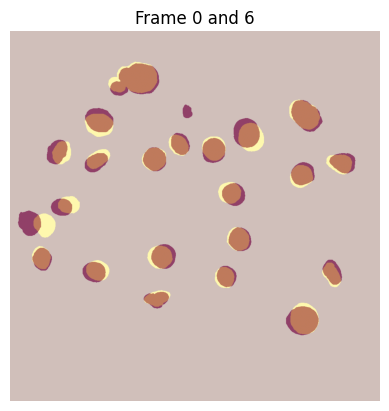

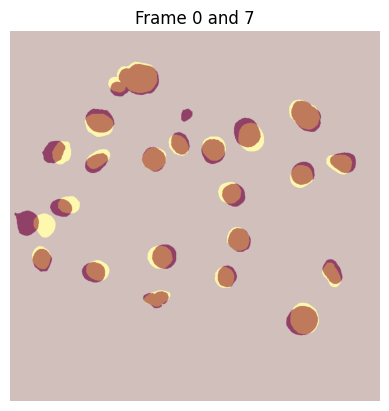

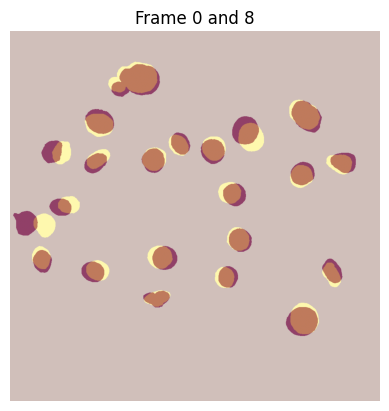

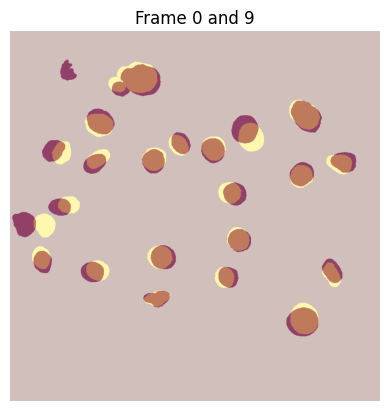

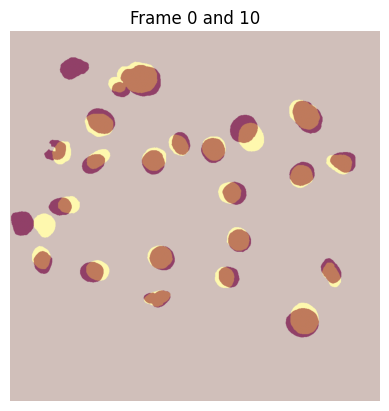

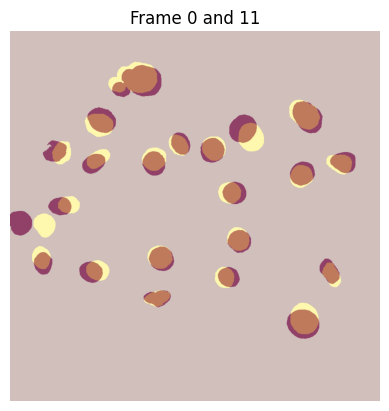

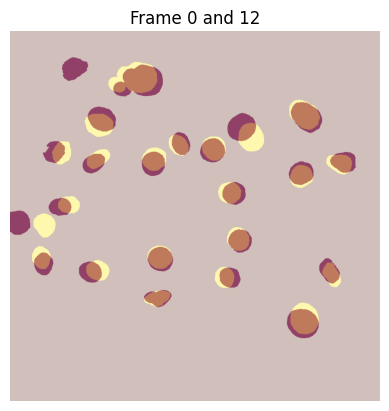

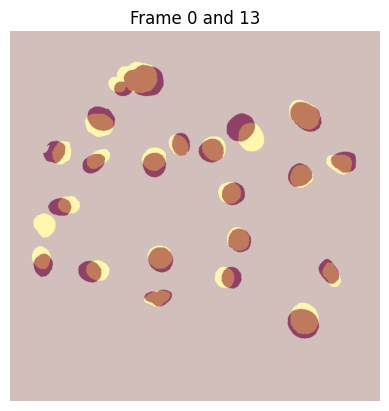

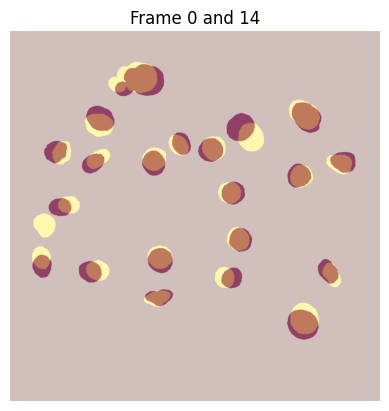

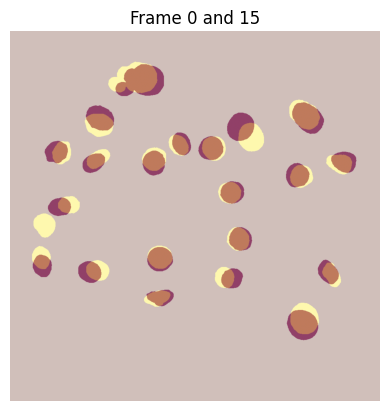

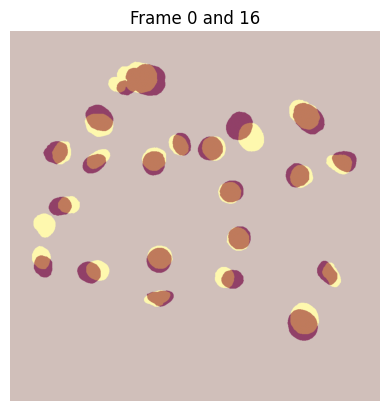

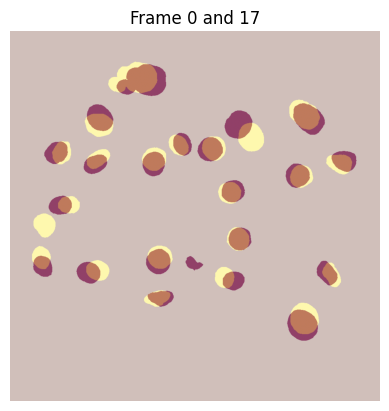

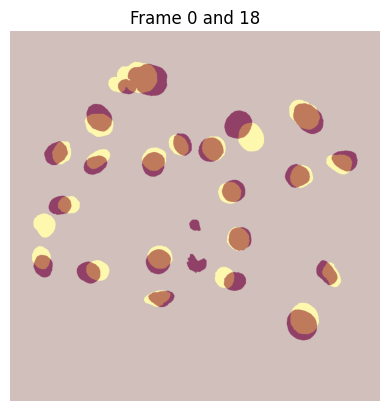

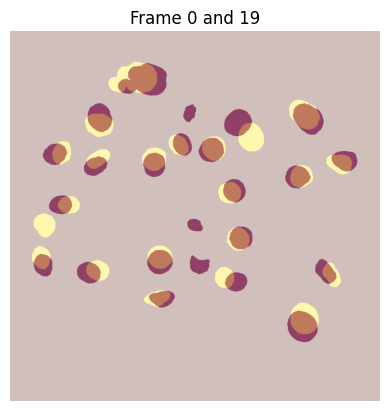

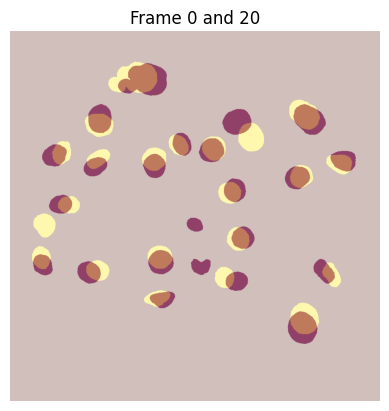

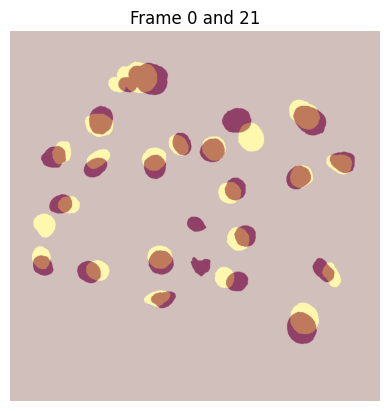

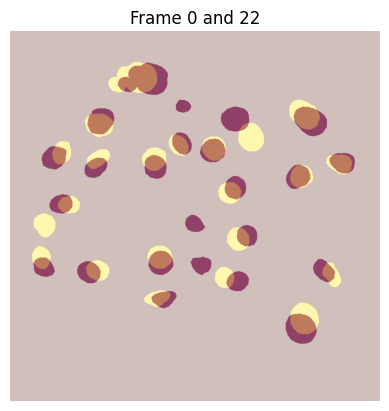

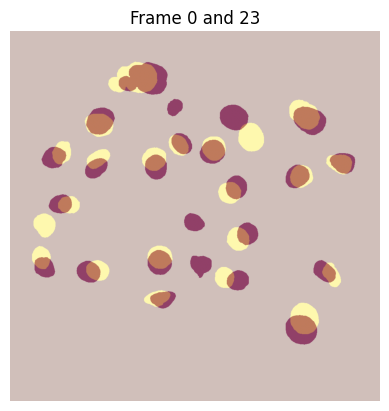

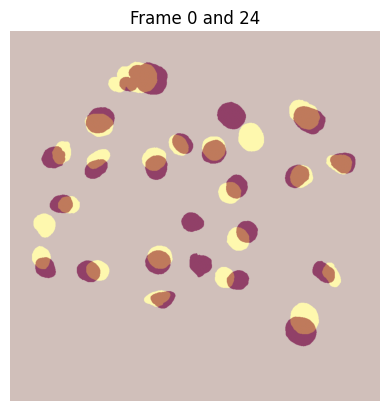

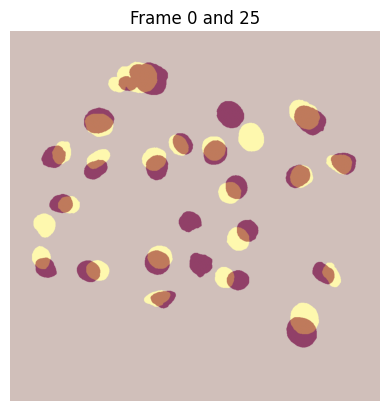

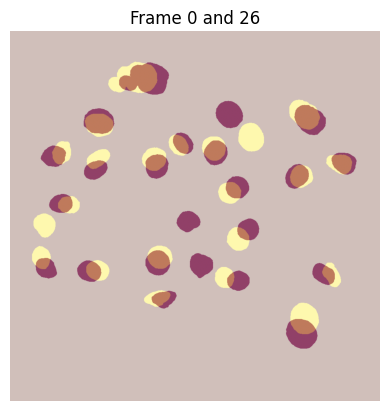

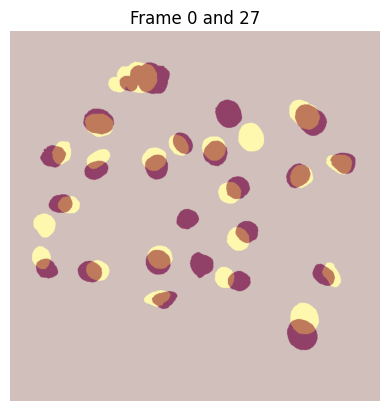

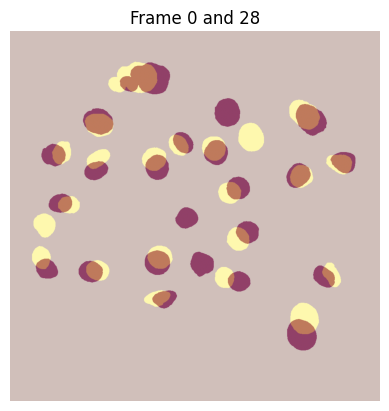

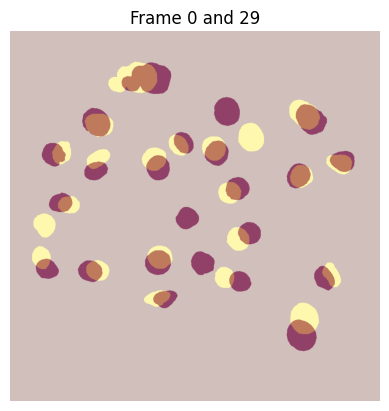

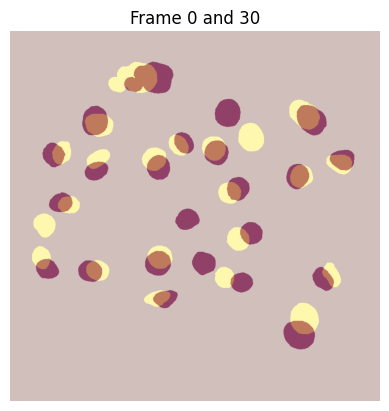

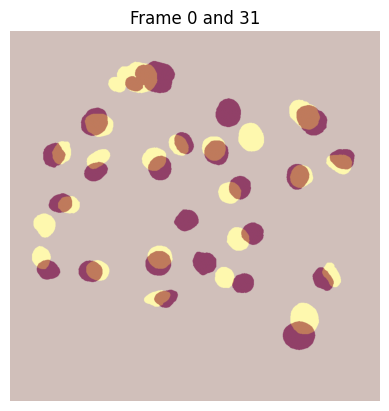

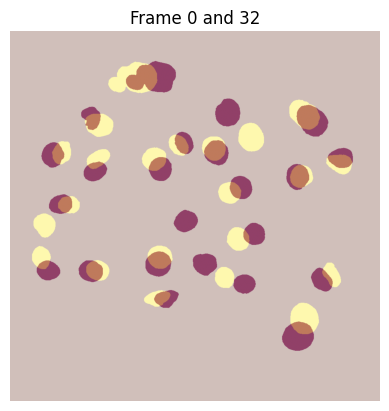

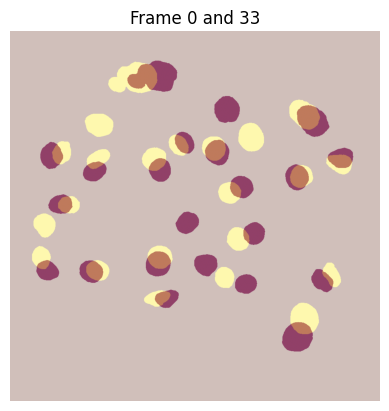

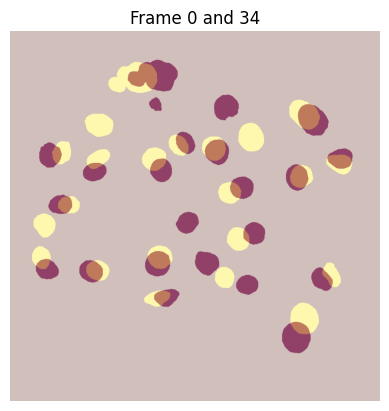

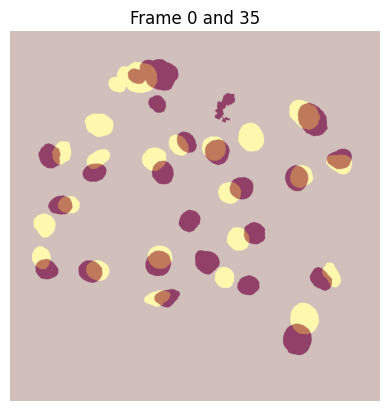

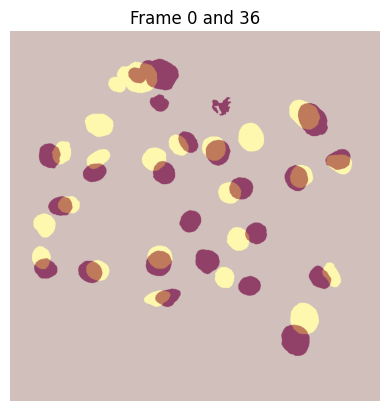

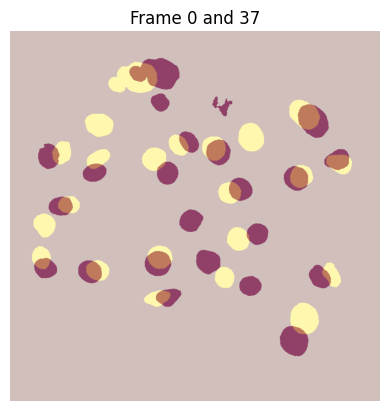

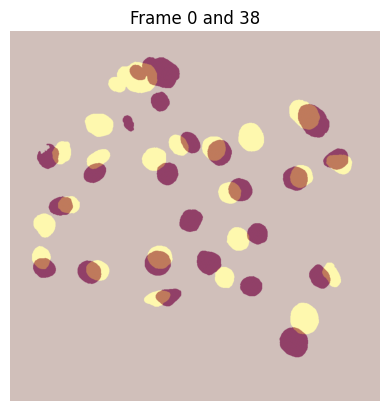

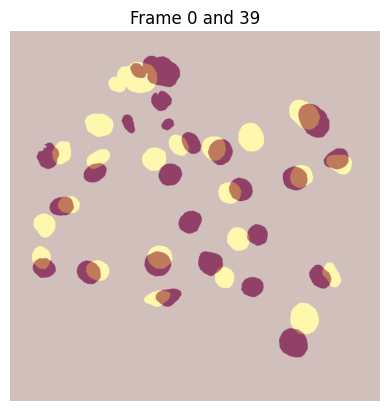

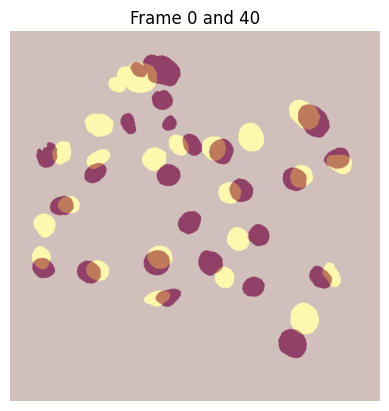

In [29]:
# Load video frames
seg_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02_ERR_SEG_TRA").iterdir())

#TODO add : for idx in range(len(seg_path_list) - 1):
for gap in range(1, 41):
    idx = 0
    idx2 = idx + gap
    seg_moving = tiff.imread(seg_path_list[idx])
    seg_fixed = tiff.imread(seg_path_list[idx2])
    seg_moving = interpole_and_pad(seg_moving, [HEIGHT, WIDTH])
    seg_fixed = interpole_and_pad(seg_fixed, [HEIGHT, WIDTH])
    seg_moving = np.where(seg_moving > 0, 1, 0)
    seg_fixed = np.where(seg_fixed > 0, 1, 0)
    plt.imshow(seg_moving, alpha=0.5)
    plt.imshow(seg_fixed, cmap="YlOrRd", alpha=0.5)
    plt.title(f"Frame {idx} and {idx2}")
    plt.axis("off")
    plt.show()

# Label visualisation

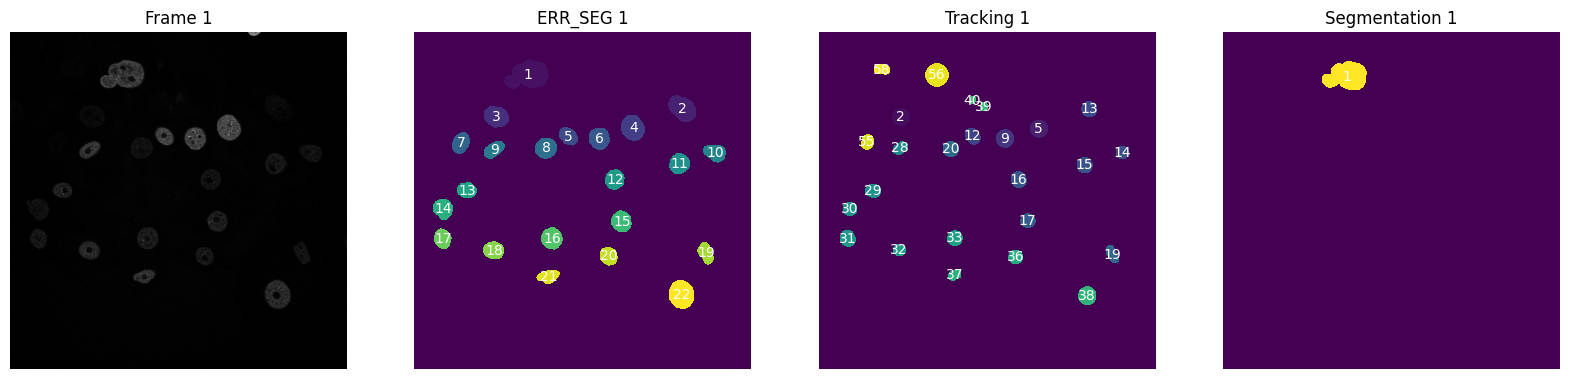

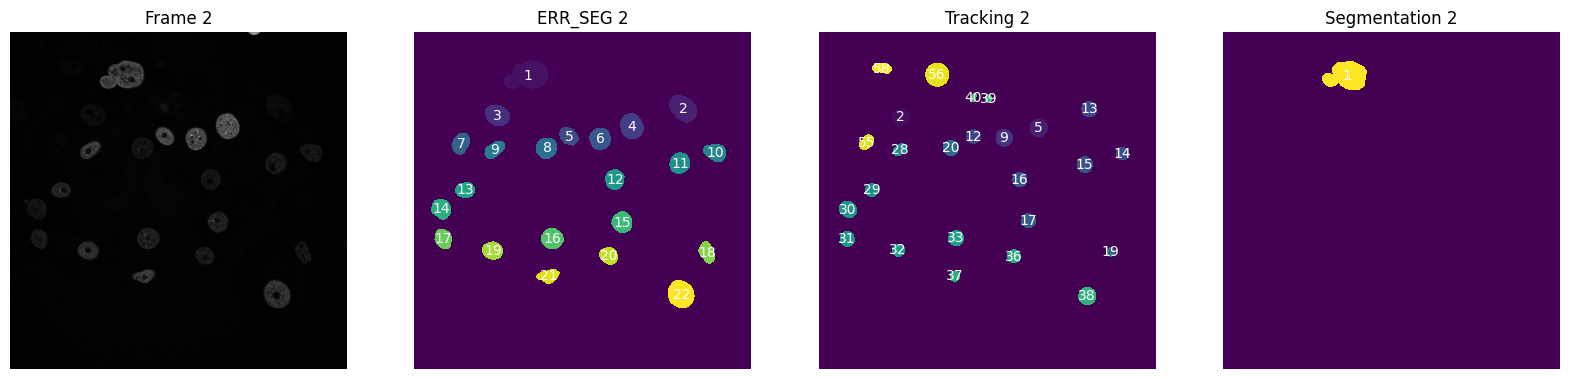

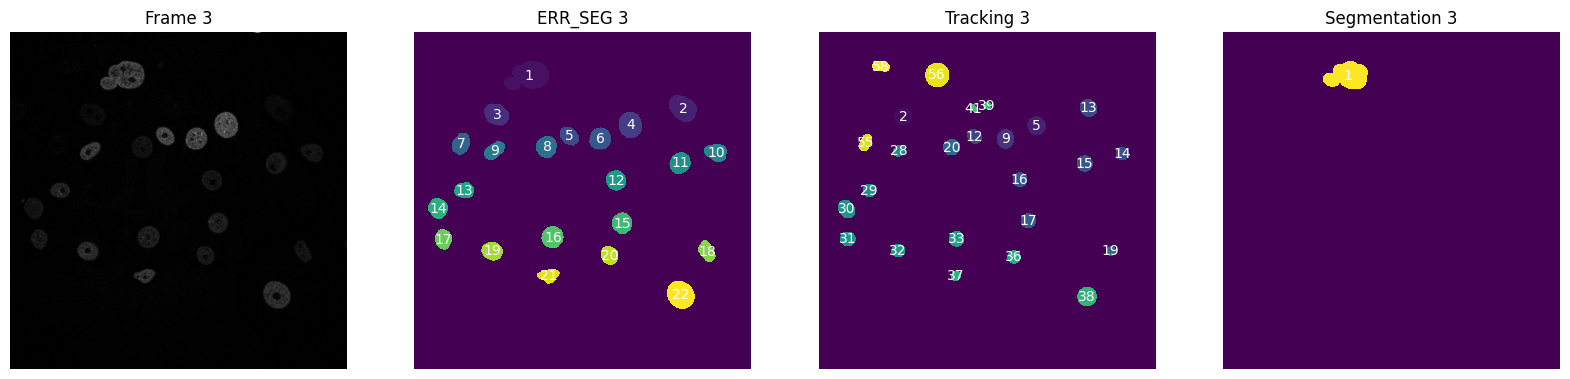

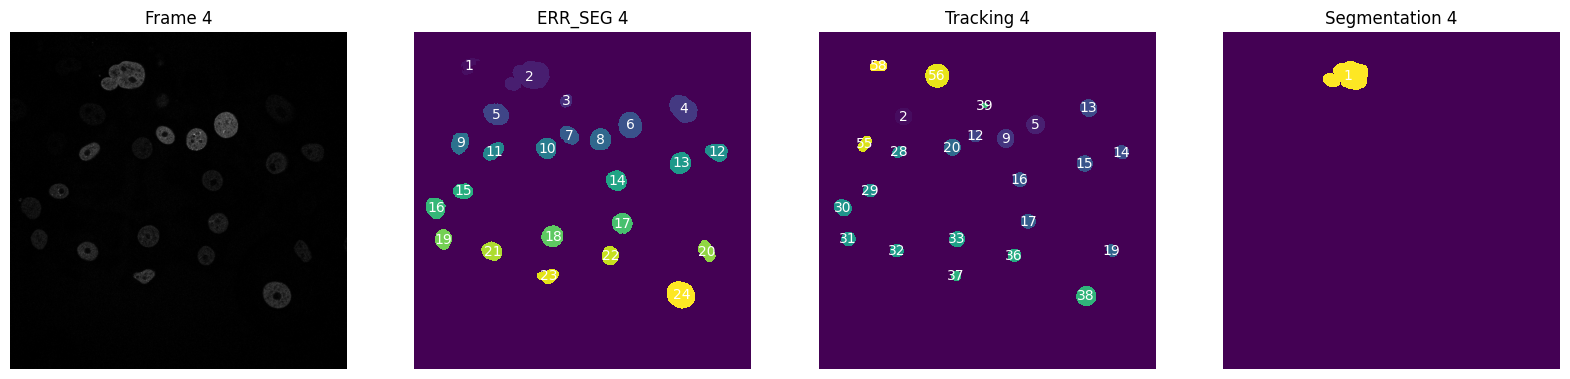

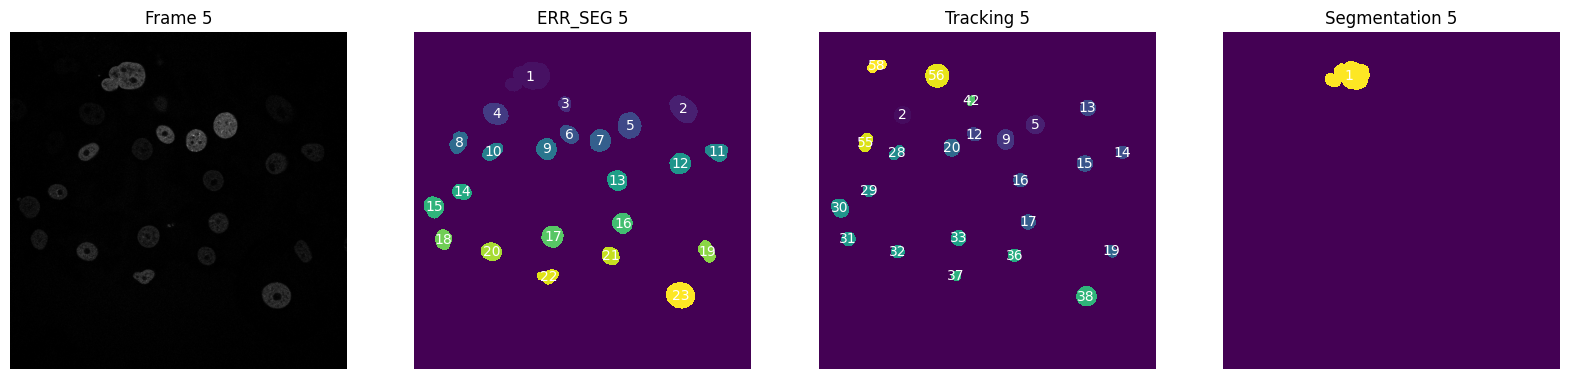

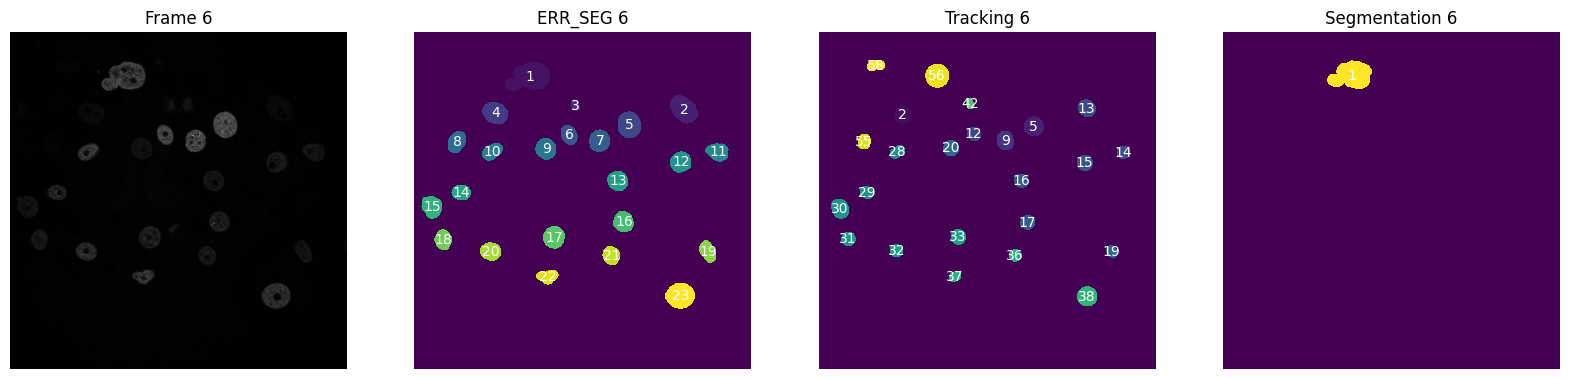

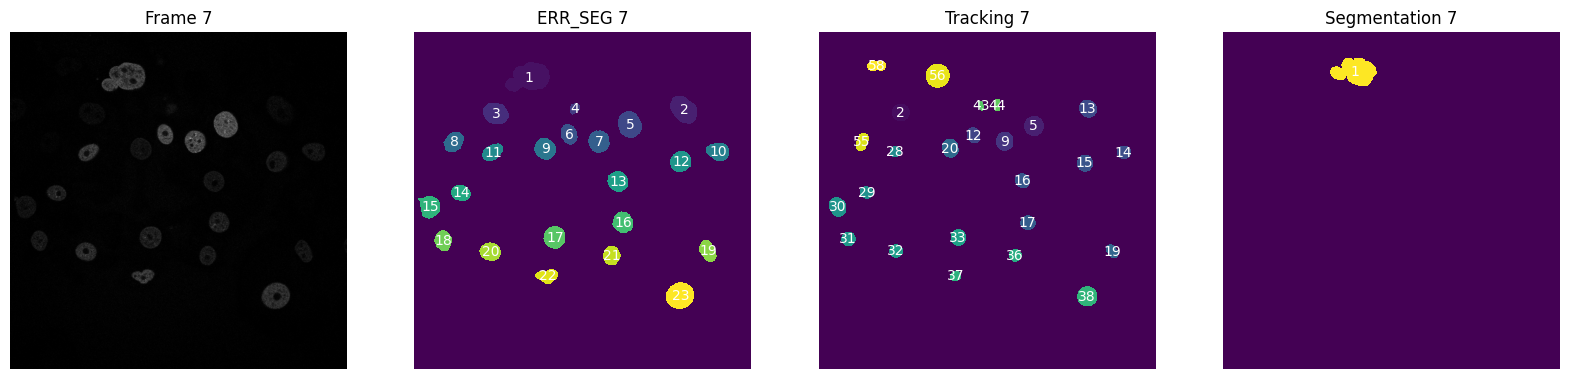

In [20]:
img_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02").iterdir())
err_seg_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02_ERR_SEG").iterdir())
tra_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02_GT/TRA").iterdir())
seg_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02_GT/SEG").iterdir())

for idx in range(1, 8):
    fig, axes = plt.subplots(1,4,figsize=(20, 5))
    img = tiff.imread(img_path_list[idx])
    axes[0].imshow(img, cmap="gray")
    axes[0].set_title(f"Frame {idx}")
    axes[0].axis("off")

    err_seg = tiff.imread(err_seg_path_list[idx])
    axes[1].set_title(f"ERR_SEG {idx}")
    visualize_labels(err_seg, ax=axes[1])

    tra = tiff.imread(tra_path_list[idx])
    axes[2].set_title(f"Tracking {idx}")
    visualize_labels(tra, ax=axes[2])

    seg = tiff.imread(seg_path_list[idx])
    axes[3].set_title(f"Segmentation {idx}")
    visualize_labels(seg, ax=axes[3])
    plt.show()


## Creation of ERR_SEG_TRA

Create new dataset with relabeled ERR_SEG using TRA

In [6]:
# Fluo-N2DH-GOWT1 02
err_seg_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DH-GOWT1_train/02_ERR_SEG").iterdir() if f.suffix == ".tif")
tra_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DH-GOWT1_train/02_GT/TRA").iterdir() if f.suffix == ".tif")
output_path = Path("data/train_data/Fluo-N2DH-GOWT1_train/02_ERR_SEG_TRA")
output_path.mkdir(exist_ok=True)
for idx in range(len(err_seg_path_list)):
    err_seg = tiff.imread(err_seg_path_list[idx])
    tra = tiff.imread(tra_path_list[idx])
    relabeled = relabel_cells(err_seg, tra)
    tiff.imwrite(output_path / f"relabeled_{idx:02d}.tif", relabeled)

ValueError: <COMPRESSION.LZW: 5> requires the 'imagecodecs' package

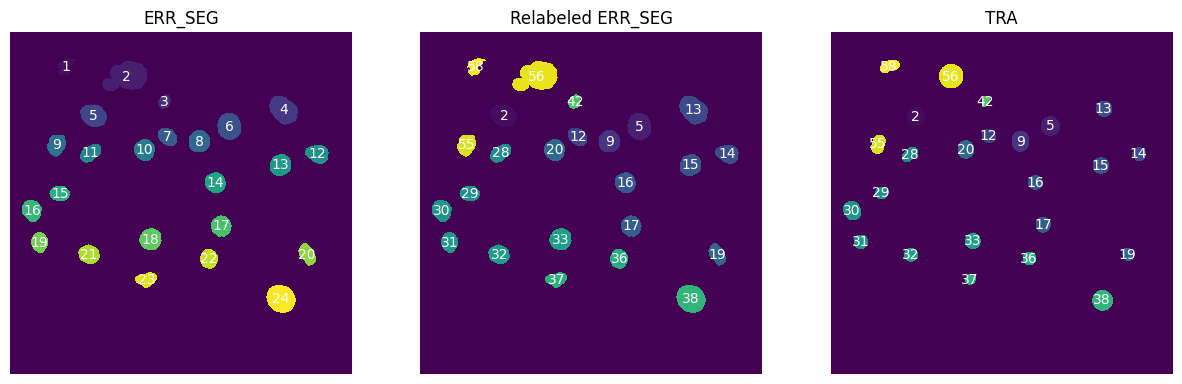

In [ ]:
# Verification
idx = 4
err_seg = tiff.imread(err_seg_path_list[idx])
tra = tiff.imread(tra_path_list[idx])
err_seg_tra_path_list = sorted(Path("data/train_data/Fluo-N2DH-GOWT1_train/02_ERR_SEG_TRA").iterdir())
relabeled = tiff.imread(err_seg_tra_path_list[idx])
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].set_title("ERR_SEG")
visualize_labels(err_seg, ax=ax[0])
ax[1].set_title("Relabeled ERR_SEG")
visualize_labels(relabeled, ax=ax[1])
ax[2].set_title("TRA")
visualize_labels(tra, ax=ax[2])

In [30]:
# Fluo-N2DH-GOWT1 01
err_seg_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DH-GOWT1_train/01_ERR_SEG").iterdir() if f.suffix == ".tif")
tra_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DH-GOWT1_train/01_GT/TRA").iterdir() if f.suffix == ".tif")
output_path = Path("data/train_data/Fluo-N2DH-GOWT1_train/01_ERR_SEG_TRA")
output_path.mkdir(exist_ok=True)
for idx in range(len(err_seg_path_list)):
    err_seg = tiff.imread(err_seg_path_list[idx])
    tra = tiff.imread(tra_path_list[idx])
    relabeled = relabel_cells(err_seg, tra)
    tiff.imwrite(output_path / f"relabeled_{idx:02d}.tif", relabeled)

In [31]:
# Fluo-N2DL-HeLa_train 01
err_seg_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DL-HeLa_train/01_ERR_SEG").iterdir() if f.suffix == ".tif")
tra_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DL-HeLa_train/01_GT/TRA").iterdir() if f.suffix == ".tif")
output_path = Path("data/train_data/Fluo-N2DL-HeLa_train/01_ERR_SEG_TRA")
output_path.mkdir(exist_ok=True)
for idx in range(len(err_seg_path_list)):
    err_seg = tiff.imread(err_seg_path_list[idx])
    tra = tiff.imread(tra_path_list[idx])
    relabeled = relabel_cells(err_seg, tra)
    tiff.imwrite(output_path / f"relabeled_{idx:02d}.tif", relabeled)

In [ ]:
# Fluo-N2DL-HeLa_train 02 - ajout segmentation dans entrainement
err_seg_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DL-HeLa_train/02_ERR_SEG").iterdir() if f.suffix == ".tif")
tra_path_list = sorted(f for f in Path("data/train_data/Fluo-N2DL-HeLa_train/02_GT/TRA").iterdir() if f.suffix == ".tif")
output_path = Path("data/train_data/Fluo-N2DL-HeLa_train/02_ERR_SEG_TRA")
output_path.mkdir(exist_ok=True)
for idx in range(len(err_seg_path_list)):
    err_seg = tiff.imread(err_seg_path_list[idx])
    tra = tiff.imread(tra_path_list[idx])
    relabeled = relabel_cells(err_seg, tra)
    tiff.imwrite(output_path / f"relabeled_{idx:02d}.tif", relabeled)

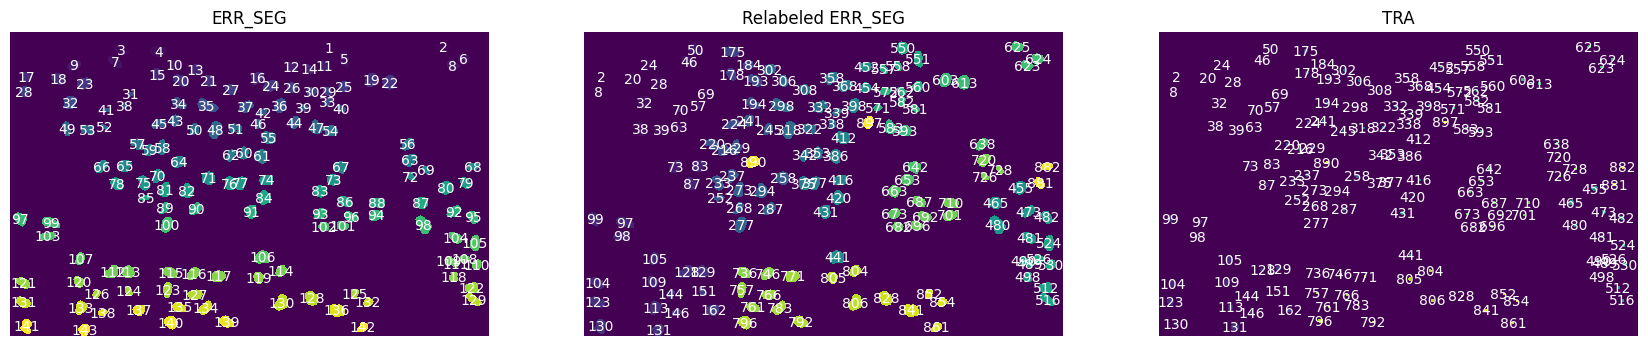

In [34]:
# Verification
idx = 4
err_seg = tiff.imread(err_seg_path_list[idx])
tra = tiff.imread(tra_path_list[idx])
err_seg_tra_path_list = sorted(Path("data/train_data/Fluo-N2DL-HeLa_train/02_ERR_SEG_TRA").iterdir())
relabeled = tiff.imread(err_seg_tra_path_list[idx])
fig, ax = plt.subplots(1, 3, figsize=(21, 7))
ax[0].set_title("ERR_SEG")
visualize_labels(err_seg, ax=ax[0])
ax[1].set_title("Relabeled ERR_SEG")
visualize_labels(relabeled, ax=ax[1])
ax[2].set_title("TRA")
visualize_labels(tra, ax=ax[2])

# To understand grid_sample / vxm.spatial_transform

In [24]:
input = torch.arange(4*4).view(1, 1, 4, 4).float()
print(input)

# Create grid to upsample input
d = torch.linspace(-1, 1, 4)
meshx, meshy = torch.meshgrid((d, d))
grid = torch.stack((meshy, meshx), 2)
grid = grid.unsqueeze(0) # add batch dim

# Create coordinate meshgrid
size = 4
y = np.linspace(-1, 1, size)
x = np.linspace(-1, 1, size)
yy, xx = np.meshgrid(y, x)

# Create deformation: radial outward displacement
# Distance from center
r = np.sqrt(xx**2 + yy**2)
# Radial deformation strength
deform_strength = 0.3
# Displacement components (pointing outward from center)
disp_y = deform_strength * yy / (r + 0.1)  # avoid division by zero
disp_x = deform_strength * xx / (r + 0.1)

# Create the deformed grid (original + displacement)
grid_y_deformed = yy + disp_y
grid = xx + disp_x
grid = torch.from_numpy(np.stack((grid_y_deformed, grid), axis=2)).float().unsqueeze(0)  # add batch dim

output = torch.nn.functional.grid_sample(input, grid, align_corners=True)
print(output)

output = torch.nn.functional.grid_sample(input, grid, mode="nearest", align_corners=True)
print(output)

tensor([[[[ 0.,  1.,  2.,  3.],
          [ 4.,  5.,  6.,  7.],
          [ 8.,  9., 10., 11.],
          [12., 13., 14., 15.]]]])
tensor([[[[ 0.0000,  0.5308,  1.2995,  1.4819],
          [ 2.1232,  3.6874,  5.2125,  3.9534],
          [ 5.1978,  9.7875, 11.3126,  7.0281],
          [ 5.9274,  7.8518,  8.6205,  7.4093]]]])
tensor([[[[ 0.,  1.,  2.,  3.],
          [ 4.,  5.,  6.,  7.],
          [ 8.,  9., 10., 11.],
          [12., 13., 14., 15.]]]])


NameError: name 'grid_x_deformed' is not defined

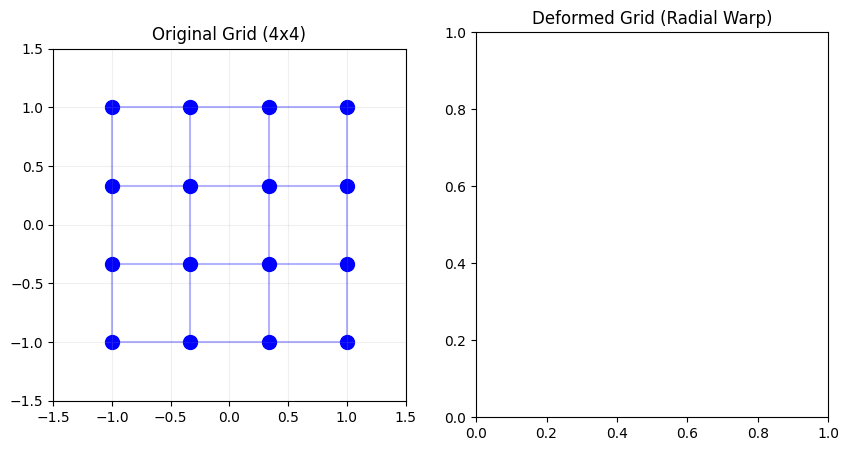

In [25]:
# Visualize with square subplots
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Set common limits
xlim = (-1.5, 1.5)
ylim = (-1.5, 1.5)

# Original grid
axes[0].set_title('Original Grid (4x4)', fontsize=12)
axes[0].scatter(xx, yy, s=100, c='blue')
for i in range(size):
    axes[0].plot(xx[i, :], yy[i, :], 'b-', alpha=0.3)
    axes[0].plot(xx[:, i], yy[:, i], 'b-', alpha=0.3)
axes[0].set_xlim(xlim)
axes[0].set_ylim(ylim)
axes[0].set_aspect('equal', adjustable='box')
axes[0].grid(True, alpha=0.2)

# Deformed grid
axes[1].set_title('Deformed Grid (Radial Warp)', fontsize=12)
axes[1].scatter(grid_x_deformed, grid_y_deformed, s=100, c='red')
for i in range(size):
    axes[1].plot(grid_x_deformed[i, :], grid_y_deformed[i, :], 'r-', alpha=0.3)
    axes[1].plot(grid_x_deformed[:, i], grid_y_deformed[:, i], 'r-', alpha=0.3)
# Draw arrows showing displacement
axes[1].quiver(xx, yy, disp_x, disp_y, alpha=0.5, scale=5)
axes[1].set_xlim(xlim)
axes[1].set_ylim(ylim)
axes[1].set_aspect('equal', adjustable='box')
axes[1].grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Displacement field shape: ({size}, {size}, 2)")
print(f"X displacement range: [{disp_x.min():.3f}, {disp_x.max():.3f}]")
print(f"Y displacement range: [{disp_y.min():.3f}, {disp_y.max():.3f}]")